In [ ]:
#!pip install opencv-python

In [43]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from glob import glob

## Reading the image:

In [ ]:
# Uncomment if you are in Google Colab:

# !pip install wget
# import wget, os
# url0 = "https://github.com/IvanSol/ml-course/raw/refs/heads/hs_2026_11/Class08_bvt_classic_cv/data/"
# urls = [url0 + fn for fn in ['cat.png', 'day00.png', 'day01.jpg', 'day02.jpg', 'day03.jpg', 'day04.jpg', 'night00.jpg', 'night01.jpg', 'night02.png', 'night03.jpg', 'night04.png', 'board.png']]
# os.makedirs('data', exist_ok=True)   
# for url in urls:
#   wget.download(url, out=os.path.join('data', url.split('/')[-1]))

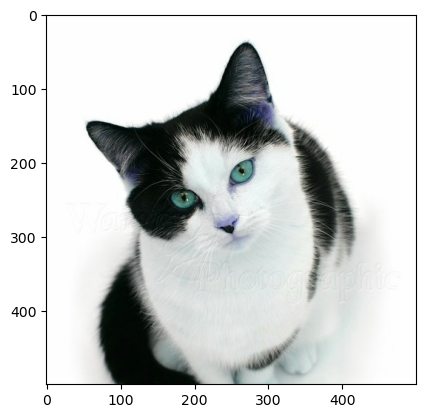

In [50]:
cat = cv2.imread('data/cat.png')
plt.imshow(cat)

### Colors seem to be incorrect. This happens because opencv by default stores images as BGR, not RGB.
There is a special function for converting the colors:

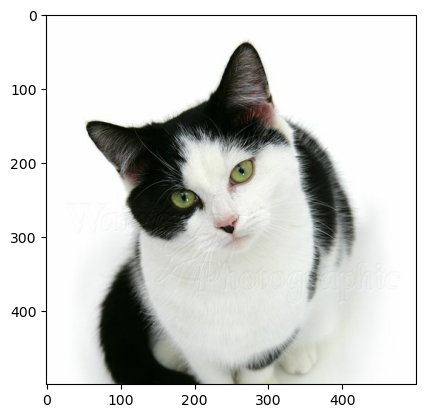

In [52]:
cat_rgb = cv2.cvtColor(cat, cv2.COLOR_BGR2RGB)
plt.imshow(cat_rgb)

Image is stored as 3-d array: (H, W, C), C -- channels. For RGB image there are 3 channels: R, G, B.

In [54]:
cat.shape

(500, 500, 3)

So, actually, to turn BGR image to RGB we may just inverse order of channels:

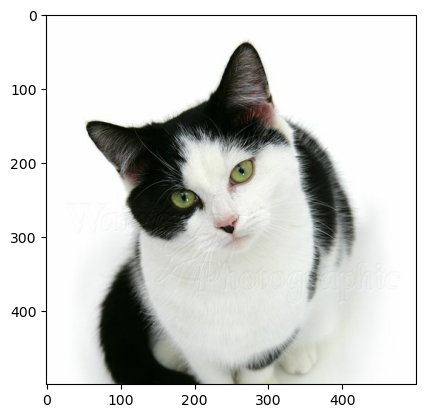

In [57]:
cat_rgb2 = cat[:,:,::-1]
plt.imshow(cat_rgb2)

Classical computer vision algorithms often work with grayscale image, so, let us convert image to grayscale:

(500, 500)


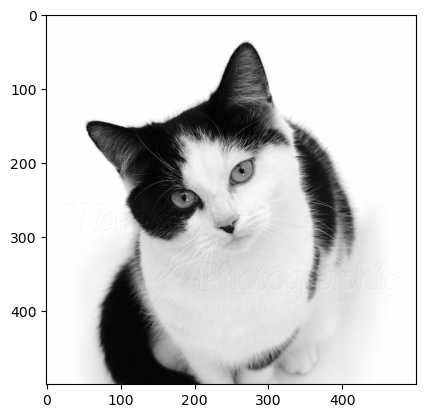

In [71]:
cat_gray = cv2.cvtColor(cat, cv2.COLOR_BGR2GRAY)
print(cat_gray.shape)
plt.imshow(cat_gray, cmap='gray')

Sometimes we may select some parts of the image according to some criteria, then selected parts may be stored in binary image which contains 0 or 1:

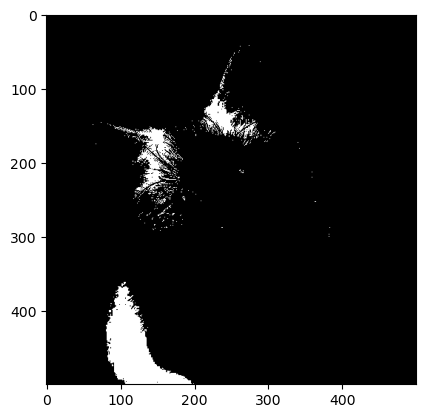

In [63]:
cat_bin = cat_gray < 10
plt.imshow(cat_bin, cmap='gray')

In [79]:
def get_kernel(n):
    # Let's define our kernel size
    kernel = np.zeros((n+(1-n%2),n+(1-n%2)), np.uint8)
    kernel = cv2.circle(kernel, (n//2, n//2), n//2, 1, -1)
    return kernel    

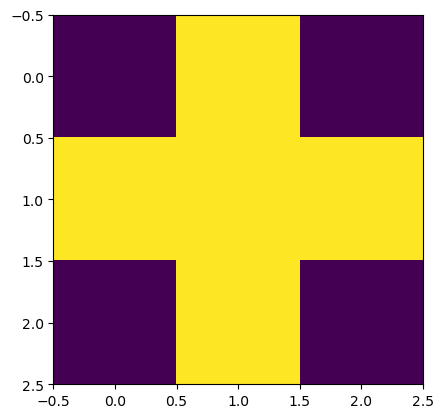

In [87]:
plt.imshow(get_kernel(3))

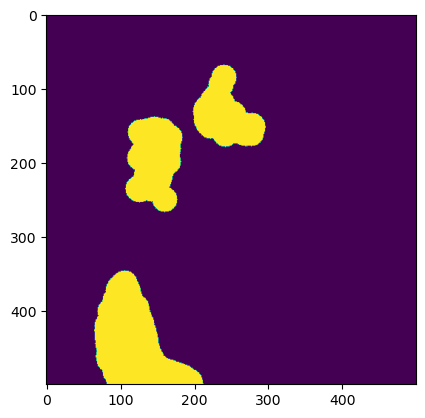

In [91]:
# Now we erode
cat_2 = cv2.erode(cat_bin.astype(np.uint8), get_kernel(3))
cat_2 = cv2.dilate(cat_2.astype(np.uint8), get_kernel(35))
plt.imshow(cat_2)

4


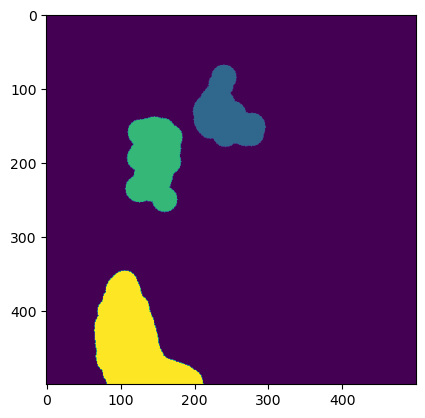

In [106]:
info, component_map = cv2.connectedComponents(cat_2.astype(np.uint8))
print(info)
plt.imshow(component_map)

## Task: Write a function to calculate how many red circles are there on the image (3 points).

In [100]:
W, H = 1000, 1000
img = np.ones((H, W, 3)) * 255
colors = [(255, 0, 0), (0, 255, 0), (0, 0, 255)]
for i in range(100):
    ok = False
    while not ok:
        x, y = np.random.randint(0, 1000, 2)
        min_r = min([50, x, y, W - x, H - y])
        if min_r <= 10:
            continue
        r = np.random.randint(10, min_r)
        c = colors[np.random.randint(3)]
        m = img[y - r : y + r + 1, x - r : x + r + 1]
        mask = np.ones_like(m) * 255
        cv2.circle(mask, (r, r), r, 0, -1)
        if (m[mask > 0] == 255).all():
            ok = True
            img = cv2.circle(img, (x, y), r, c, -1)
#plt.imshow(img)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


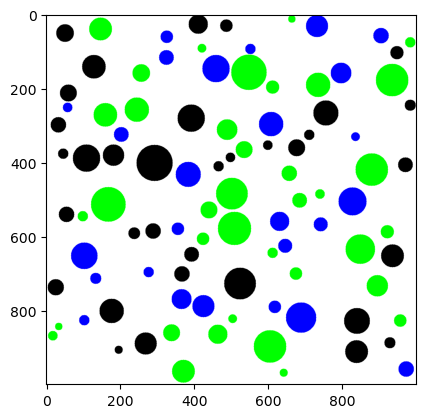

In [180]:
plt.imshow(img)

In [ ]:
def count_red_circles(img):
    pass # YOUR CODE HERE

In [156]:
mask = (img == (255,0,0)).all(axis=2)

In [162]:
count, m = cv2.connectedComponents(mask.astype(np.uint8))

In [178]:
img[mask] = (0,0,0)

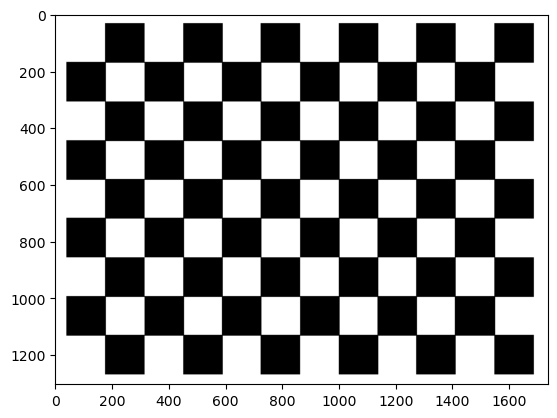

In [182]:
img = cv2.imread('data/board.png', cv2.IMREAD_GRAYSCALE)
plt.imshow(img, cmap='gray')

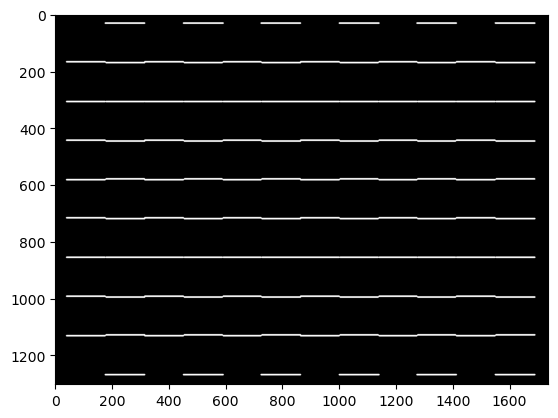

In [184]:
gray = abs(img[1:].astype(float) - img[:-1].astype(float))
gray = cv2.dilate(gray.astype(np.uint8), get_kernel(5))
plt.imshow(gray>0, cmap='gray')

In [ ]:
# It contains code with geometrical functions to calculate distance between lines:
#from remove_similar_lines import remove_similar_lines

def detect_lines(gray, threshold=10, min_line_length=1000, max_line_gap=100):
    """
    Detects lines on the image using Hough transform.
    """
    blurred = (cv2.GaussianBlur(gray, (3, 3), 0) > 0).astype(np.uint8)
    lines = cv2.HoughLinesP(blurred, 
                            rho=1, 
                            theta=np.pi/180, 
                            threshold=100,
                            minLineLength=min_line_length,
                            maxLineGap=max_line_gap)
    
    image_with_lines = np.zeros_like(gray)
    # This function calculates paiwise distances between lines and removes ones which are close to each other.
    lines = remove_similar_lines([l[0] for l in lines])
    
    # Draw found lines:
    if lines is not None:
        for line in lines:
            x1, y1, x2, y2 = line
            cv2.line(image_with_lines, (x1, y1), (x2, y2), 255, 2)
    
    return image_with_lines, lines

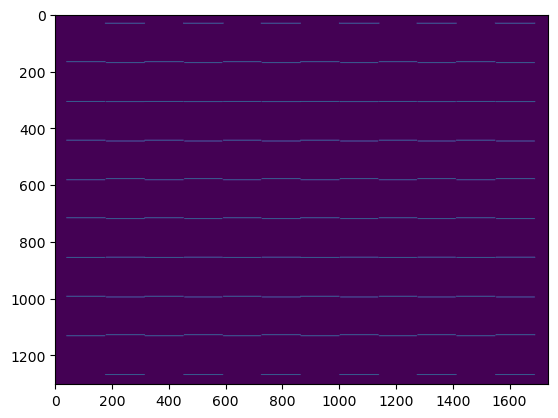

In [188]:
grad_y = abs(img[1:] - img[:-1]).mean()
plt.imshow(grad_y)
plt.show()

Lines found: 8
[array([  39,  308, 1688,  308], dtype=int32), array([  39,  718, 1688,  718], dtype=int32), array([  39, 1130, 1688, 1130], dtype=int32), array([  39,  169, 1688,  169], dtype=int32), array([  39,  855, 1688,  855], dtype=int32), array([  39,  994, 1688,  994], dtype=int32), array([  39,  581, 1688,  581], dtype=int32), array([  39,  445, 1688,  445], dtype=int32)]


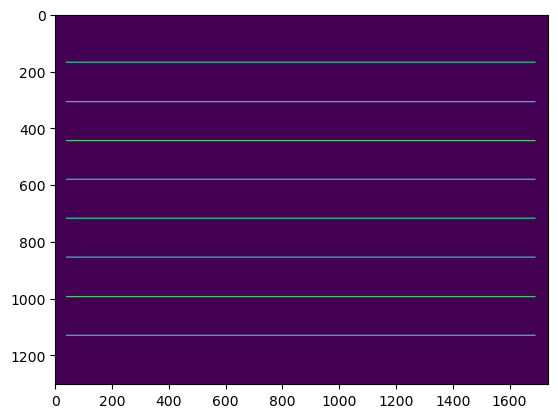

In [192]:
result_image, lines = detect_lines(grad_y)
print(f"Lines found: {len(lines) if lines is not None else 0}")
plt.imshow(result_image)
print(lines)

## Task: Color all black cells in even rows with green (5 points).

In [ ]:
def recolor_even_rows(img):
    pass # YOUR CODE HERE

## Image classification

In [194]:
day_imgs = []
night_imgs = []
for fn in glob('data/day*'):
    day_imgs.append(cv2.imread(fn, cv2.IMREAD_GRAYSCALE))
for fn in glob('data/night*'):
    night_imgs.append(cv2.imread(fn, cv2.IMREAD_GRAYSCALE))

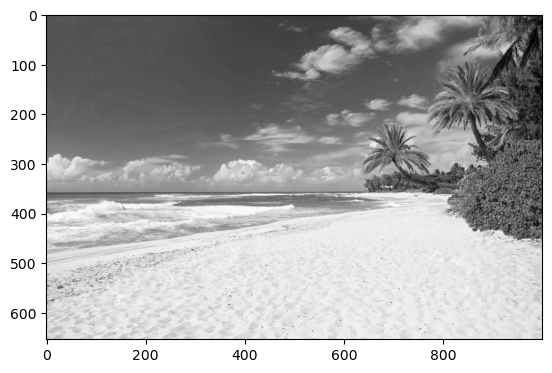

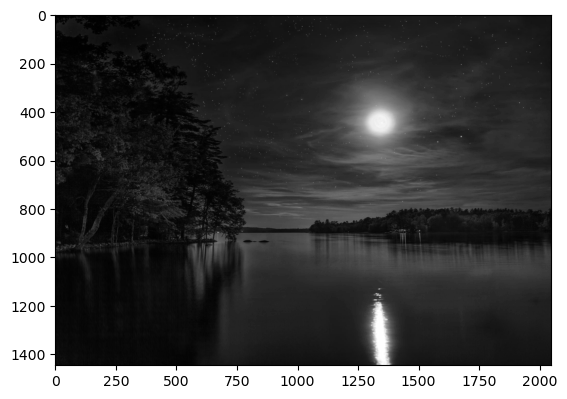

In [196]:
plt.imshow(day_imgs[0], cmap='gray')
plt.show()
plt.imshow(night_imgs[0], cmap='gray')
plt.show()

#### Here we may find features to be used for classification.

In [198]:
x_day = [img.mean() for img in day_imgs]
x_night = [img.mean() for img in night_imgs]

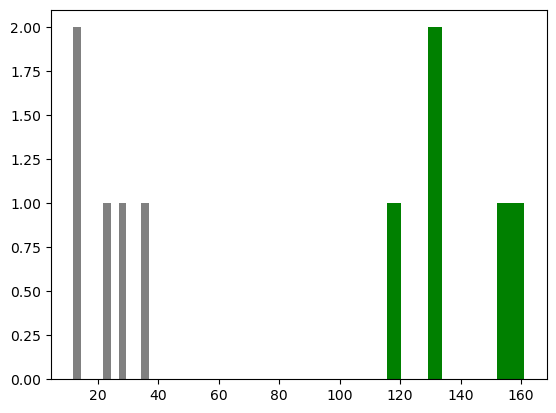

In [200]:
plt.hist(x_day, color='green')
plt.hist(x_night, color='gray')
plt.show()

In [ ]:
#code with geometrical functions to calculate distance between lines:
import numpy as np
import math
from typing import List, Tuple

def line_to_canonical(line: Tuple[float, float, float, float]) -> Tuple[float, float, float]:
    """
    Преобразует линию из формата двух точек в каноническую форму Ax + By + C = 0
    
    Параметры:
    - line: кортеж (x1, y1, x2, y2)
    
    Возвращает:
    - (A, B, C): коэффициенты канонического уравнения
    """
    x1, y1, x2, y2 = line
    
    # Вычисляем коэффициенты прямой
    A = y2 - y1
    B = x1 - x2
    C = x2 * y1 - x1 * y2
    
    # Нормализуем коэффициенты
    norm = math.sqrt(A**2 + B**2)
    if norm > 0:
        A /= norm
        B /= norm
        C /= norm
    
    return A, B, C

def point_to_line_distance(point: Tuple[float, float], line: Tuple[float, float, float]) -> float:
    """
    Вычисляет расстояние от точки до линии в канонической форме
    
    Параметры:
    - point: кортеж (x, y)
    - line: кортеж (A, B, C) канонического уравнения
    
    Возвращает:
    - distance: расстояние от точки до линии
    """
    x, y = point
    A, B, C = line
    return abs(A * x + B * y + C) / math.sqrt(A**2 + B**2)

def line_center(line: Tuple[float, float, float, float]) -> Tuple[float, float]:
    """
    Вычисляет центр линии
    """
    x1, y1, x2, y2 = line
    return ((x1 + x2) / 2, (y1 + y2) / 2)

def line_angle(line: Tuple[float, float, float]) -> float:
    """
    Вычисляет угол линии в радианах [0, pi)
    """
    A, B, C = line
    if B == 0:
        return math.pi / 2  # Вертикальная линия
    return math.atan2(-A, B) % math.pi

def lines_distance(line1_canonical: Tuple[float, float, float], 
                  line2_canonical: Tuple[float, float, float],
                  line1_points: Tuple[float, float, float, float] = None,
                  line2_points: Tuple[float, float, float, float] = None,
                  method: str = 'combined') -> float:
    """
    Вычисляет расстояние между двумя линиями в канонической форме
    
    Параметры:
    - line1_canonical, line2_canonical: канонические формы линий (A, B, C)
    - line1_points, line2_points: исходные точки линий (для некоторых методов)
    - method: метод вычисления расстояния:
      'parallel' - расстояние между параллельными линиями
      'angle' - угловое расстояние
      'center' - расстояние между центрами линий
      'combined' - комбинированная метрика
      'hausdorff' - расстояние Хаусдорфа (требует точки)
    
    Возвращает:
    - distance: расстояние между линиями
    """
    A1, B1, C1 = line1_canonical
    A2, B2, C2 = line2_canonical
    
    if method == 'parallel':
        # Расстояние между параллельными линиями
        # Проверяем параллельность (скалярное произведение нормалей ≈ 1)
        dot_product = abs(A1 * A2 + B1 * B2)
        if dot_product < 0.95:  # Линии не параллельны
            return float('inf')
        
        # Для параллельных линий расстояние |C2 - C1| / sqrt(A^2 + B^2)
        # Но так как коэффициенты нормализованы, sqrt(A^2 + B^2) = 1
        return abs(C2 - C1)
    
    elif method == 'angle':
        # Угловое расстояние
        angle1 = line_angle(line1_canonical)
        angle2 = line_angle(line2_canonical)
        angle_diff = min(abs(angle1 - angle2), math.pi - abs(angle1 - angle2))
        return angle_diff * 100  # Масштабируем для сравнения с другими метриками
    
    elif method == 'center':
        # Расстояние между центрами линий
        if line1_points is None or line2_points is None:
            raise ValueError("Для метода 'center' нужны исходные точки линий")
        
        center1 = line_center(line1_points)
        center2 = line_center(line2_points)
        dx = center1[0] - center2[0]
        dy = center1[1] - center2[1]
        return math.sqrt(dx**2 + dy**2)
    
    elif method == 'combined':
        # Комбинированная метрика, учитывающая угол и смещение
        if line1_points is None or line2_points is None:
            raise ValueError("Для метода 'combined' нужны исходные точки линий")
        
        # Угловое расстояние
        angle1 = line_angle(line1_canonical)
        angle2 = line_angle(line2_canonical)
        angle_diff = min(abs(angle1 - angle2), math.pi - abs(angle1 - angle2))
        
        # Расстояние между центрами
        center1 = line_center(line1_points)
        center2 = line_center(line2_points)
        center_distance = math.sqrt((center1[0] - center2[0])**2 + (center1[1] - center2[1])**2)
        
        # Расстояние от центров до противоположных линий
        dist1_to_2 = point_to_line_distance(center1, line2_canonical)
        dist2_to_1 = point_to_line_distance(center2, line1_canonical)
        line_distance = (dist1_to_2 + dist2_to_1) / 2
        
        # Комбинированная метрика (можно настроить веса)
        combined = (angle_diff * 50 +  # вес для угла
                   center_distance * 0.5 +  # вес для расстояния между центрами
                   line_distance * 1.0)  # вес для расстояния между линиями
        
        return combined
    
    elif method == 'hausdorff':
        # Расстояние Хаусдорфа (максимальное из минимальных расстояний)
        if line1_points is None or line2_points is None:
            raise ValueError("Для метода 'hausdorff' нужны исходные точки линий")
        
        # Извлекаем точки из линий
        points1 = [(line1_points[0], line1_points[1]), (line1_points[2], line1_points[3])]
        points2 = [(line2_points[0], line2_points[1]), (line2_points[2], line2_points[3])]
        
        # Вычисляем расстояние Хаусдорфа
        max_min_dist = 0
        for p1 in points1:
            min_dist = min(point_to_line_distance(p1, line2_canonical) for p2 in points2)
            max_min_dist = max(max_min_dist, min_dist)
        
        for p2 in points2:
            min_dist = min(point_to_line_distance(p2, line1_canonical) for p1 in points1)
            max_min_dist = max(max_min_dist, min_dist)
        
        return max_min_dist
    
    else:
        raise ValueError(f"Неизвестный метод: {method}")

def calculate_line_distances(lines: List[Tuple[float, float, float, float]], 
                           method: str = 'combined') -> np.ndarray:
    """
    Вычисляет матрицу попарных расстояний между линиями
    
    Параметры:
    - lines: список линий в формате [(x1, y1, x2, y2), ...]
    - method: метод вычисления расстояния
    
    Возвращает:
    - distance_matrix: матрица N x N расстояний между линиями
    """
    n = len(lines)
    distance_matrix = np.zeros((n, n))
    
    # Преобразуем все линии в каноническую форму
    canonical_lines = [line_to_canonical(line) for line in lines]
    
    # Вычисляем попарные расстояния
    for i in range(n):
        for j in range(i + 1, n):
            distance = lines_distance(
                canonical_lines[i], 
                canonical_lines[j],
                lines[i] if method in ['center', 'combined', 'hausdorff'] else None,
                lines[j] if method in ['center', 'combined', 'hausdorff'] else None,
                method
            )
            distance_matrix[i, j] = distance
            distance_matrix[j, i] = distance
    
    return distance_matrix

def find_similar_lines(lines: List[Tuple[float, float, float, float]], 
                      threshold: float = 10.0,
                      method: str = 'combined') -> List[List[int]]:
    """
    Находит группы похожих линий на основе матрицы расстояний
    
    Параметры:
    - lines: список линий
    - threshold: порог для определения похожести
    - method: метод вычисления расстояния
    
    Возвращает:
    - groups: список групп индексов похожих линий
    """
    distance_matrix = calculate_line_distances(lines, method)
    n = len(lines)
    visited = set()
    groups = []
    
    for i in range(n):
        if i in visited:
            continue
        
        # Начинаем новую группу с линии i
        group = [i]
        visited.add(i)
        
        # Ищем все линии, близкие к текущей группе
        for j in range(n):
            if j not in visited and distance_matrix[i, j] <= threshold:
                group.append(j)
                visited.add(j)
        
        groups.append(group)
    
    return groups

def remove_similar_lines(lines: List[Tuple[float, float, float, float]], 
                        threshold: float = 10.0,
                        method: str = 'combined',
                        keep_longest: bool = True) -> List[Tuple[float, float, float, float]]:
    """
    Удаляет похожие линии, оставляя по одной из каждой группы
    
    Параметры:
    - lines: список линий
    - threshold: порог для определения похожести
    - method: метод вычисления расстояния
    - keep_longest: если True, оставляет самую длинную линию в группе
    
    Возвращает:
    - unique_lines: список уникальных линий
    """
    def line_length(line):
        x1, y1, x2, y2 = line
        return math.sqrt((x2 - x1)**2 + (y2 - y1)**2)
    
    groups = find_similar_lines(lines, threshold, method)
    unique_lines = []
    
    for group in groups:
        if keep_longest:
            # Оставляем самую длинную линию в группе
            longest_line = max([lines[i] for i in group], key=line_length)
            unique_lines.append(longest_line)
        else:
            # Оставляем первую линию в группе
            unique_lines.append(lines[group[0]])
    
    return unique_lines